# 11 · 真实竞赛：从题目走到一条预测
## 目标
为缺少交互的市场 t1、t2 推荐商品，利用 s1、s2、s3 的共享商品信息。
你将读取**完整官方数据**，从 100 件给定商品中排序。每个用户只有一个验证正例，成功指标是 nDCG@10。

本轮以 [OPDAI 冠军公开方案](https://github.com/opdai/wsdm2022-xmrec-top1-solution)为依据。
[官方排行榜](https://xmrec.github.io/wsdmcup/)冠军分数 0.6773 是当年隐藏测试成绩，**本地不会把验证成绩冒充这个分数**。
这里复现了冠军核心算法与两阶段流程，缩小图模型、特征集合和集成规模。完整差异见[复现说明](../docs/XMREC_REPRODUCTION.md)。

顺序：[12 特征](12_XMRec_Features.ipynb) → [13 采样与图模型](13_XMRec_Graph.ipynb) → [14 重训排序器](14_XMRec_Ranking.ipynb) → [15 评估](15_XMRec_Evaluation.ipynb)。
## 准备
当前内核使用项目 .venv。下载只需首次执行 `python -m reclab.competition prepare`；本轮已经下载并核对校验和。

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd()
if not (ROOT / "reclab").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
from reclab.competition import data
from reclab.competition.teaching import load_run, style, bar_scores
style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
run, rows, features = load_run()
print("实际训练快照:", run.name)

Matplotlib is building the font cache; this may take a moment.


实际训练快照: 20261030T115556803593-cloud-restore


## 步骤 1 · 先明确哪些文件能进训练
`train.tsv` 是评分交互；`train_5core.tsv` 是经过筛选的正反馈，不是未点击曝光。
冠军将 5core 的评分改成 5，再按 user-item 去重，优先保留原 train 的记录。
目标市场的 qrel 不能进入特征训练语料。官方没有公开隐藏测试标签。

In [2]:
summary = []
for market in data.MARKETS:
    train = data.interactions(market)
    combined = data.corpus([market])
    summary.append({"market": market, "raw_train_rows": len(train),
                    "duplicate_user_item_pairs": int(train.duplicated(["userId", "itemId"]).sum()),
                    "merged_rows": len(combined), "users": combined.userId.nunique(),
                    "items": combined.itemId.nunique()})
summary = pd.DataFrame(summary)
display(summary)
display(data.interactions("t1").head(5))

,market,raw_train_rows,duplicate_user_item_pairs,merged_rows,users,items
0,s1,840212,39564,809095,141508,35518
1,s2,115549,1147,130077,20327,5172
2,s3,54202,789,57113,8627,2922
3,t1,60168,1392,60400,9955,3543
4,t2,120320,1690,120178,18504,8919


,userId,itemId,rating
0,t1U1006129,P1016853,5.0
1,t1U1002135,P1019605,5.0
2,t1U1006710,P1032538,5.0
3,t1U1007418,P1012632,5.0
4,t1U1008062,P1022775,5.0


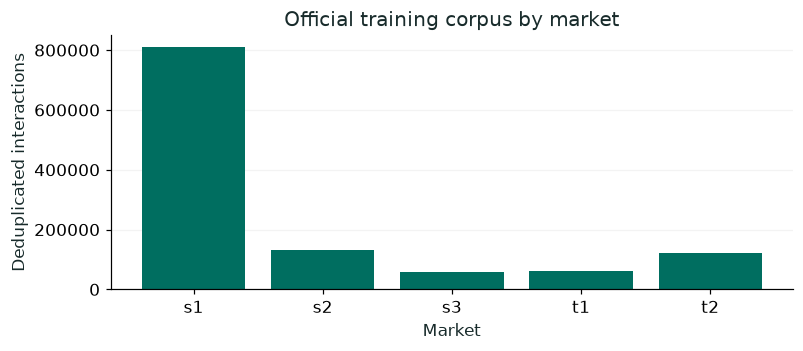

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(summary.market, summary.merged_rows, color="#006e60")
ax.set(xlabel="Market", ylabel="Deduplicated interactions", title="Official training corpus by market")
ax.grid(axis="y", alpha=.15)
plt.show()

## 步骤 2 · 跟踪一个真实用户
每行不是一次曝光；它是竞赛给定的候选商品之一。`label=0` 表示不是本次被留出的那个正例，不能解释成真实业务“不喜欢”。
用户和商品 ID 都已匿名化，数据没有时间戳、商品标题、价格或可解释的国家名。不能在这里伪造“最近 7 天热度”等特征。

In [4]:
user = rows.query("market == 't1'").userId.iloc[0]
example = rows[(rows.market == "t1") & (rows.userId == user)]
known = data.corpus(["t1"])
display(known[known.userId.eq(user)].head(10))
display(example.head(8))
print("候选数:", len(example), "正例数:", int(example.label.sum()))
print("正例 ID:", example.loc[example.label.eq(1), "itemId"].iloc[0])

,userId,itemId,rating
6380,t1U1005570,P1030052,5.0
7115,t1U1005570,P1021106,5.0
9808,t1U1005570,P1014278,5.0
12074,t1U1005570,P1020517,5.0
13319,t1U1005570,P1031263,4.0


,userId,itemId,market,label,partition
0,t1U1005570,P1005811,t1,0,fit
1,t1U1005570,P1035751,t1,0,fit
2,t1U1005570,P1007542,t1,0,fit
3,t1U1005570,P1035694,t1,0,fit
4,t1U1005570,P1006599,t1,0,fit
5,t1U1005570,P1012377,t1,0,fit
6,t1U1005570,P1026761,t1,0,fit
7,t1U1005570,P1004549,t1,0,fit


候选数: 100 正例数: 1
正例 ID: P1026107


## 步骤 3 · 查看实际运行结果的来源
全数据特征生成后，官方验证用户按稳定哈希分为约 60% fit、20% select、20% audit。
fit 训练排序器，select 选模型，选定后才查看 audit。所有候选行跟着用户一起分组。
**原方案是 10 折行级 bagging；此处改成用户隔离的本地实验流程。**

In [5]:
receipt = json.loads((run / "receipt.json").read_text())
display(pd.Series(receipt))
display(rows.groupby(["market", "partition"]).userId.nunique().unstack())
assert rows.groupby(["market", "userId"]).partition.nunique().eq(1).all()
source = json.loads(data.SPEC.read_text())
print("官方数据版本:", source["official_revision"])
print("冠军源码版本:", source["winner_revision"])
print("原始文件校验数:", len(source["files"]))

run_id                  20261030T115556803593-cloud-restore
selected                                         lgb_memory
seconds                                          164.998926
peak_rss_mib                                    1782.796875
official_valid_users                                   8179
features                                                 21
status                                                 PASS
hidden_test_score                                      None
lightgbm_threads                                          1
dtype: object

partition,audit,fit,select
market,,,
t1,543,1616,538
t2,1062,3267,1153


官方数据版本: f5b1f087a4054537cd8f46bf346f978094b8467e
冠军源码版本: 8af3260368b1980a85a555fc470caa84bf6697d6
原始文件校验数: 22


## 检查理解
如果把 qrel 的正例加入 t1 的交互矩阵，再评估这批用户，为什么分数会变好？
<details><summary>答案路径</summary>模型已经看到评估目标；这不是泛化提升。跨市场共享的是已知训练交互里的商品关系，不是把目标答案加入图。</details>
## 下一步
打开 12。先预测：源市场数据更多，是否一定使 t1、t2 都变好？后面用真实分数验证。